# Лекция 7. DQN: почему оценки разлетаются и как это чинит целевая сеть

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/IlyaChichkanov/Reinforcement-learning/blob/main/07-dqn-stability/lecture/lecture.ipynb)

**Главный вопрос сегодня: почему Q-сеть с буфером опыта выдаёт оценки, которых не бывает, — и как целевая сеть возвращает их на место?**

На прошлой лекции мы заменили таблицу $Q$ нейросетью и добавили буфер опыта: шест стал стоять в несколько раз дольше, но оценки $Q$ ушли в тысячи. Сегодня найдём причину на примере из двух состояний и уберём её одной добавкой — целевой сетью. Q-сеть + буфер опыта + целевая сеть — это **DQN** (Deep Q-Network). В конце тем же алгоритмом посадим лунный модуль.

1. Где мы остановились: шест стоит, оценки неправдоподобны
2. Почему оценки разлетаются
3. Целевая сеть: цель считает медленная копия. Это и есть DQN
4. Тот же DQN сажает лунный модуль
5. Double DQN: кто выбирает действие в цели
6. Итоги и где это работает

In [1]:
# Ноутбук считается около 11 минут, вывод сохранён. QUICK = True — быстрый прогон с другими числами.
QUICK = False                                     # True — один запуск и 200 эпизодов вместо трёх и 300
SEEDS = range(1) if QUICK else range(3)
EPISODES = 200 if QUICK else 300

# Служебные модули. В репозитории они лежат рядом; в Google Colab скачиваются заново при каждом запуске.
import pathlib, sys, urllib.error, urllib.request
RAW = "https://raw.githubusercontent.com/IlyaChichkanov/Reinforcement-learning/"
MODULES = (("dqn_plots", "06-dqn/lecture"), ("dqn_core", "07-dqn-stability/lecture"),
           ("dqn7_plots", "07-dqn-stability/lecture"), ("cartpole_plots", "05-policy-gradient/seminar"))
for name, folder in MODULES:
    local = pathlib.Path("../..") / folder / f"{name}.py"
    if local.exists():
        sys.path.append(str(local.parent))
        continue
    for branch in ("main", "claude/reinforcement-learning-intro-u4zlwz"):   # пока лекция не влита в main — из ветки
        try:
            urllib.request.urlretrieve(f"{RAW}{branch}/{folder}/{name}.py", f"{name}.py"); break
        except urllib.error.HTTPError:
            continue
import importlib.util, subprocess
for package in ("gymnasium", "torch"):
    if importlib.util.find_spec(package) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], check=True)

In [2]:
import time
from collections import deque
import numpy as np
import matplotlib.pyplot as plt
import torch
from dqn_core import *            # код прошлой лекции: make_qnet, epsilon_greedy, to_tensors, td_targets, q_of, q_max, train_qnet
from dqn_plots import make_cartpole, plot_runs, plot_q_start, plot_q_lag, plot_grid_2x2, play_greedy
from dqn7_plots import *          # схемы и картинки этой лекции
from cartpole_plots import animate_cartpole
torch.set_num_threads(1)          # маленькой сети один поток быстрее
start_time = time.time()

## 1. Где мы остановились: шест стоит, оценки неправдоподобны

**Главная идея: Q-сеть, которая учится на пачках из буфера опыта, держит шест долго, но её оценки $Q$ уходят далеко за возможный предел.**

Что мы собрали на прошлой лекции:

* **Q-сеть** получает состояние CartPole — четыре числа — и выдаёт два: $Q_\theta(s, \leftarrow)$ и $Q_\theta(s, \rightarrow)$; $\theta$ — её веса.
* **Буфер опыта** — журнал переходов $(s, a, r, s', \text{конец})$. Шаг обучения делается на пачке из 64 случайных переходов.
* **Цель** для каждого перехода — как в Q-learning: $y = r + \gamma\,(1 - \text{конец}) \max_{a'} Q_\theta(s', a')$. Шаг градиента уменьшает ошибку $\big(y - Q_\theta(s, a)\big)^2$.

На схеме — один шаг такого обучения. Красная стрелка — то, о чём сегодняшняя лекция: цель считает та же сеть, которую мы учим.

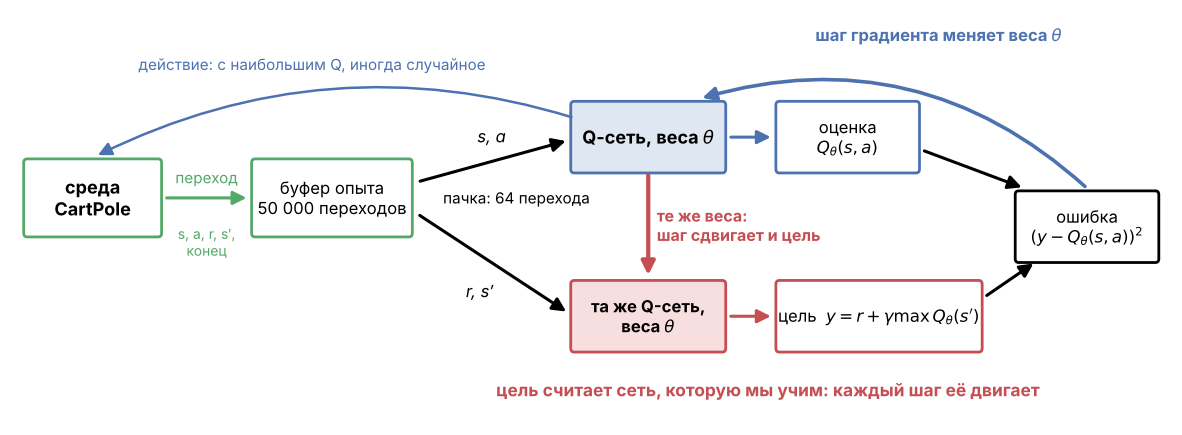

In [3]:
draw_dqn_scheme(target=False)
plt.show()

**Вопрос 1.** Пока шест стоит, агент получает $+1$ за шаг; $\gamma = 0.99$, эпизод не длиннее 500 шагов. После обучения сеть оценила стартовое состояние: $\max_a Q = 3698$. Может ли ценность старта быть такой?

* **A.** да, если шест стоит очень долго;
* **B.** нет: больше 100 не бывает;
* **C.** нет: больше 500 не бывает — в эпизоде 500 шагов;
* **D.** да: $Q$ — условные очки, а не сумма наград.

Повторим обучение прошлой лекции — `train_qnet`, три запуска по 300 эпизодов — в двух вариантах: шаг обучения на пачке из буфера и, для сравнения, по шагу подряд — на одном только что сделанном переходе. Мерок две: сколько шагов стоит шест и какова оценка старта.

по шагу подряд  шест в эпизодах 100–300: [83. 75. 52.] шагов,  наибольшая оценка старта: [75. 98. 58.]
буфер           шест в эпизодах 100–300: [348. 331. 206.] шагов,  наибольшая оценка старта: [  1584.   3698. 210279.]


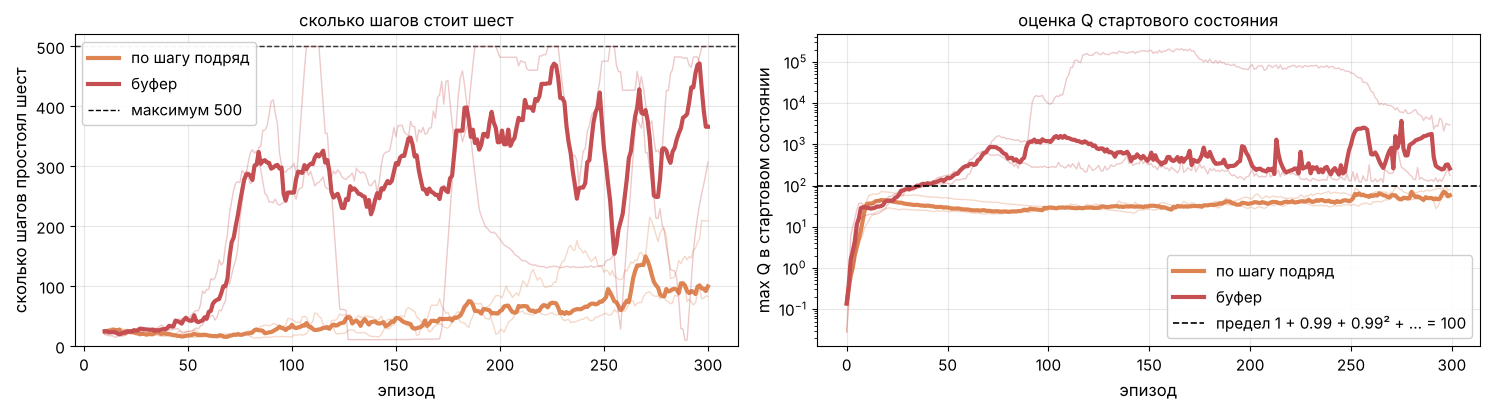

In [4]:
runs = {"по шагу подряд": [train_qnet(seed, replay=False, episodes=EPISODES) for seed in SEEDS],
        "буфер": [train_qnet(seed, replay=True, episodes=EPISODES) for seed in SEEDS]}
lengths = {name: np.array([run[0] for run in rows]) for name, rows in runs.items()}   # длины эпизодов: запуски × эпизоды
q_start = {name: np.array([run[1] for run in rows]) for name, rows in runs.items()}   # оценки старта: запуски × эпизоды
for name in runs:
    print(f"{name:15s} шест в эпизодах 100–{EPISODES}: {lengths[name][:, 100:].mean(axis=1).round(0)} шагов,"
          f"  наибольшая оценка старта: {np.abs(q_start[name]).max(axis=1).round(0)}")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
plot_runs(lengths, ax=axes[0], title="сколько шагов стоит шест")
plot_q_start(q_start, ax=axes[1], title="оценка Q стартового состояния")
plt.tight_layout(); plt.show()

Ответ **B — нет, больше 100 не бывает**. Даже если шест стоит вечно, сумма наград с дисконтом равна $1 + 0.99 + 0.99^2 + \dots = \dfrac{1}{1 - 0.99} = 100$. Вариант с 500 забывает про дисконт.

А сеть с буфером выдала больше во всех трёх запусках: наибольшая оценка старта — 1584, 3698 и 210 279. Играет она при этом хорошо: шест стоит 206–348 шагов в эпизодах 100–300 против 52–83 по шагу подряд. У сети без буфера оценки за предел не вышли: 58–98.

> **Простыми словами.** Играет сеть хорошо, а её оценки в десятки и тысячи раз больше того, что в этой игре можно получить.

**Одной строкой:** с буфером опыта Q-сеть учится быстро, но её оценки $Q$ уходят далеко за предел 100.

## 2. Почему оценки разлетаются

**Главная идея: цель считает та же сеть, которую мы учим, — шаг к цели поднимает и саму цель.**

Самый маленький пример, где это видно (Саттон и Барто, раздел 11.2). Состояний два, все награды 0 — настоящая ценность обоих состояний 0. Оценки задаёт один вес $w$: $\hat v(1) = w$, $\hat v(2) = 2w$ — как у сети, где одни веса отвечают за много состояний. В данных только переход $1 \to 2$. Обновление — как у Q-сети: цель $= 0 + \gamma\,\hat v(2) = 1.8\,w$ при $\gamma = 0.9$, шаг $w \leftarrow w + 0.1\,(1.8\,w - w)$.

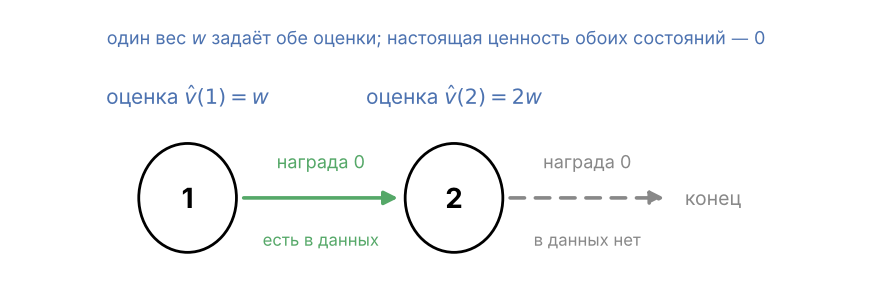

In [5]:
draw_two_states_scheme()
plt.show()

**Вопрос 2.** Начинаем с $w = 1$ и делаем 100 таких шагов. Что будет с оценкой $\hat v(1) = w$?

* **A.** придёт к 0 — награды же нулевые;
* **B.** останется около 1;
* **C.** вырастет до тысяч;
* **D.** будет колебаться вокруг 0.

Первые 12 шагов. Слева наш пример; справа то же самое, но оценки хранит таблица — у состояния 2 своё число, от $w$ оно не зависит.

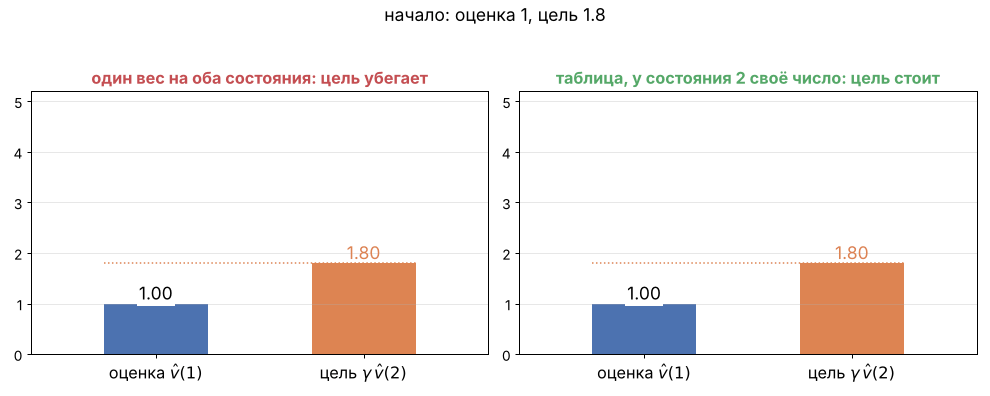

Ответ **C — вырастет до тысяч**. Каждый шаг умножает $w$ на $1.08$, за 100 шагов это $1.08^{100} \approx 2200$ — хотя наград нет вовсе. Вес $w$ поднимает обе оценки, вторую вдвое сильнее, поэтому цель $1.8\,w$ всегда впереди оценки $w$. В таблице цель от шага не зависит, и оценка просто приходит к ней.

**Когда так бывает.** Нужны три условия сразу, их называют **смертельной триадой** (deadly triad):

1. **аппроксимация** — одни веса задают оценки многих состояний;
2. **бутстрэппинг** — в цели стоит своя же оценка;
3. **off-policy** — данные собрала не та стратегия, которую оцениваем.

Без любого из трёх оценки не разлетаются. Третье условие Q-сети добавил буфер: в нём лежат переходы всех прошлых версий стратегии. Пока сеть училась по шагу подряд, её оценки за предел 100 не выходили.

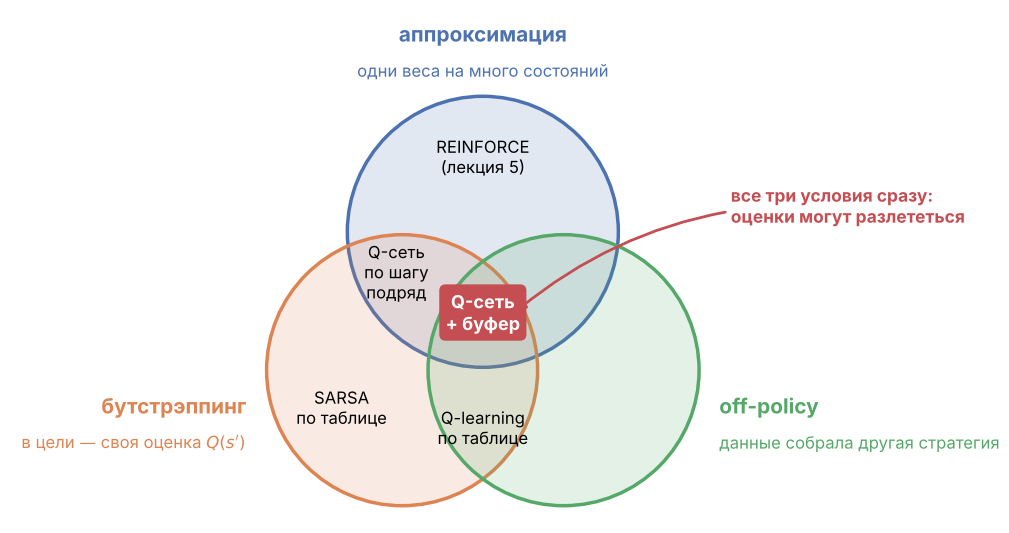

In [6]:
draw_triad()
plt.show()

> **Простыми словами.** Это как догонять собственную тень: шагаешь к ней — она отодвигается.

**Одной строкой:** общие веса + своя оценка в цели + старые данные — и оценки могут расти без единой награды.

## 3. Целевая сеть: цель считает медленная копия. Это и есть DQN

**Главная идея: цель $y$ считает не обучаемая сеть, а её копия, которая подтягивается к оригиналу на 1 % за шаг, — шаг обучения цель больше не сдвигает.**

В ошибке веса $\theta$ стоят дважды — в цели и в оценке:

$$
\text{ошибка} \;=\; \big(\underbrace{r + \gamma\,(1 - \text{конец}) \max_{a'} Q_\theta(s', a')}_{\text{цель } y} \;-\; Q_\theta(s, a)\big)^2 .
$$

Заведём второй набор весов $\bar\theta$ — копию сети — и будем считать цель им:

$$
y \;=\; r + \gamma\,(1 - \text{конец}) \max_{a'} Q_{\bar\theta}(s', a'), \qquad\quad \bar\theta \;\leftarrow\; 0.99\,\bar\theta + 0.01\,\theta \ \ \text{после каждого шага}.
$$

Шаг градиента меняет $\theta$ и не трогает $\bar\theta$: цель для него — готовое число, как у таблицы. Оставить копию навсегда нельзя — цель застыла бы на необученной сети; поэтому копия подтягивается к $\theta$ на 1 % за шаг и отстаёт примерно на сотню шагов. Это **целевая сеть** (target network). На схеме изменилась одна деталь:

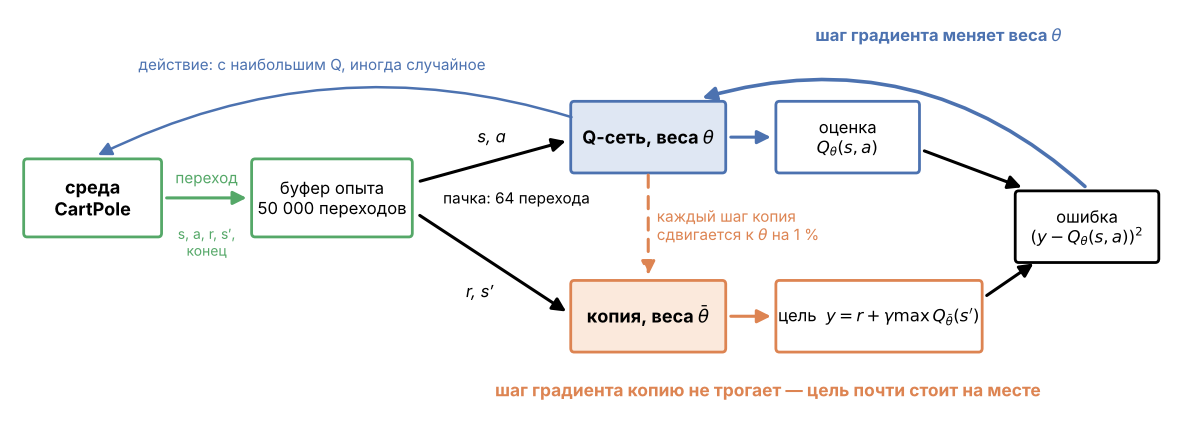

In [7]:
draw_dqn_scheme(target=True)
plt.show()

В коде сдвиг копии — одна маленькая функция:

In [8]:
def soft_update(target_net, qnet, tau=0.01):
    # θ̄ ← (1 − τ) θ̄ + τ θ: каждый вес копии сдвигается к весу основной сети на долю τ = 1 %
    with torch.no_grad():
        for w_copy, w in zip(target_net.parameters(), qnet.parameters()):
            w_copy.mul_(1 - tau).add_(tau * w)

А цикл обучения — прошлой лекции, с тремя новыми строками; они помечены `# ← новое`. В `trace` для картинки записывается оценка старта у сети и у копии на первых 4000 шагах.

In [9]:
def train_dqn(seed, replay=True, episodes=EPISODES, lr=1e-3, batch=64):
    rng, env, qnet = np.random.default_rng(seed), make_cartpole(), make_qnet(seed)
    target_net = make_qnet(seed)                                       # ← новое: копия сети, веса θ̄
    opt = torch.optim.Adam(qnet.parameters(), lr=lr)
    buffer = deque(maxlen=50_000)                                      # журнал переходов
    step, lengths, q_start, trace = 0, [], [], []
    s0 = env.reset(seed=seed * 10_000)[0]                              # стартовое состояние — для следа
    for episode in range(episodes):
        s, _ = env.reset(seed=seed * 10_000 + episode)
        q_start.append(q_max(qnet, s))                                 # число: оценка старта эпизода
        for t in range(1, 501):
            # 1. шаг в среде, переход — в журнал
            a = epsilon_greedy(qnet, s, eps=max(0.01, 1 - step / 5000), rng=rng)
            s2, r, terminated, truncated, _ = env.step(a)
            buffer.append((s, a, np.float32(r), s2, np.float32(terminated)))
            # 2. на чём учимся: список из 64 случайных переходов (или из одного последнего)
            picked = [buffer[i] for i in rng.integers(len(buffer), size=batch)] if replay else [buffer[-1]]
            S, A, R, S2, D = to_tensors(picked)                        # тензоры: S и S2 — 64 × 4; A, R, D — по 64 числа
            # 3. цель и шаг градиента
            y = td_targets(target_net, R, S2, D)                       # ← новое: цель считает копия; 64 числа
            loss = ((y - q_of(qnet, S, A)) ** 2).mean()
            opt.zero_grad(); loss.backward(); opt.step()
            # 4. копия подтягивается к основной сети
            soft_update(target_net, qnet)                              # ← новое
            if step < 4000:
                trace.append((q_max(qnet, s0), q_max(target_net, s0)))
            step += 1; s = s2
            if terminated or truncated:
                break
        lengths.append(t)
    return np.array(lengths), np.array(q_start), np.array(trace), qnet   # длины, оценки старта, след, сеть

Обучим два варианта с целевой сетью — без буфера и с буфером — и посмотрим на след: оценку стартового состояния у основной сети и у копии.

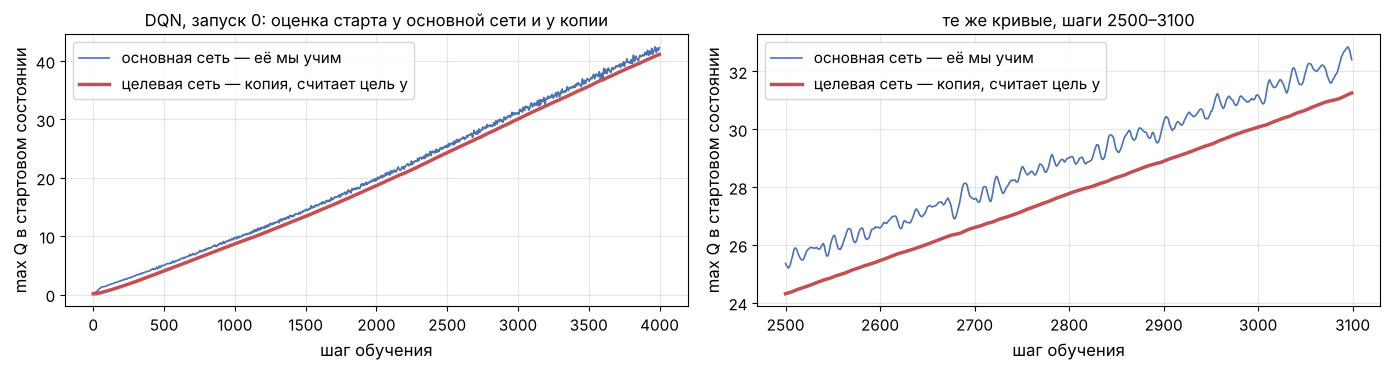

In [10]:
runs["целевая сеть"] = [train_dqn(seed, replay=False) for seed in SEEDS]
runs["буфер + целевая сеть (DQN)"] = [train_dqn(seed) for seed in SEEDS]
for name in ("целевая сеть", "буфер + целевая сеть (DQN)"):
    lengths[name] = np.array([run[0] for run in runs[name]])
    q_start[name] = np.array([run[1] for run in runs[name]])

trace = runs["буфер + целевая сеть (DQN)"][0][2]                 # запуск 0: массив 4000 × 2 — сеть и копия
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
plot_q_lag(trace, ax=axes[0], title="DQN, запуск 0: оценка старта у основной сети и у копии")
plot_q_lag(trace, ax=axes[1], window=(2500, 3100), title="те же кривые, шаги 2500–3100")
plt.tight_layout(); plt.show()

Основная сеть дёргается на каждом шаге, копия идёт за ней гладко и с запозданием около сотни шагов: пока сеть делает шаг к цели, сама цель почти стоит на месте.

> **Простыми словами.** Раньше мишень отпрыгивала после каждого выстрела. Теперь она ползёт так медленно, что в неё можно целиться.

**Вопрос 3.** Четыре варианта: буфер есть или нет × целевая сеть есть или нет. Какой будет держать шест дольше всех и при этом не разгонит оценки $Q$ до тысяч?

* **A.** только буфер;
* **B.** только целевая сеть;
* **C.** буфер и целевая сеть вместе;
* **D.** без буфера и без целевой сети.

по шагу подряд               шест в эпизодах 100–300:      [83. 75. 52.]   наибольшая оценка старта: [75. 98. 58.]
целевая сеть                 шест в эпизодах 100–300:      [33. 26. 32.]   наибольшая оценка старта: [45. 28. 36.]
буфер                        шест в эпизодах 100–300:   [348. 331. 206.]   наибольшая оценка старта: [  1584.   3698. 210279.]
буфер + целевая сеть (DQN)   шест в эпизодах 100–300:   [273. 416. 387.]   наибольшая оценка старта: [119. 114. 131.]


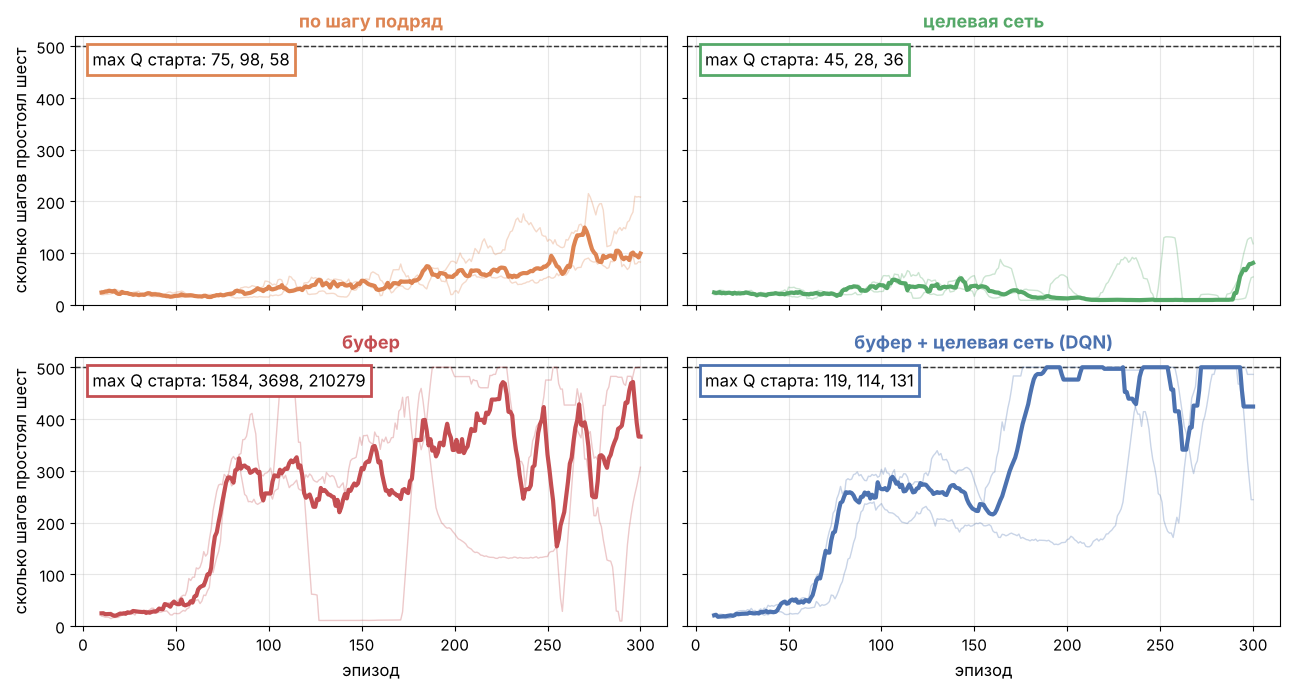

In [11]:
q_biggest = {name: np.abs(q).max(axis=1) for name, q in q_start.items()}     # наибольшая оценка старта в каждом запуске
for name in ("по шагу подряд", "целевая сеть", "буфер", "буфер + целевая сеть (DQN)"):
    print(f"{name:28s} шест в эпизодах 100–{EPISODES}: {str(lengths[name][:, 100:].mean(axis=1).round(0)):>18s}"
          f"   наибольшая оценка старта: {q_biggest[name].round(0)}")
plot_grid_2x2(lengths, q_biggest)
plt.show()

Ответ **C — буфер и целевая сеть вместе**. DQN держит шест 273–416 шагов в эпизодах 100–300, а наибольшая оценка старта — 114–131: рядом с пределом 100, а не тысячи. Один буфер держит шест почти так же долго (206–348), но оценки у него — тысячи и сотни тысяч. Одна целевая сеть почти не учится: 26–33 шага.

> **Простыми словами.** Буфер даёт сети разнообразные примеры, целевая сеть — почти неподвижную цель. По отдельности не работает: без буфера примеров мало и они однообразные, а цель ещё и запаздывает; без целевой сети цель убегает.

Целевая сеть не отменяет три условия, а замедляет круг «оценка поднимает цель»: в примере «w и 2w» с такой копией оценка тоже растёт, но в сотни раз медленнее. В CartPole этого хватает: в буфере есть переходы, где шест упал, и их цель $y = r = 1$ своей оценки не содержит.

Так держит шест сеть из лучшего запуска DQN: в каждом состоянии — действие с наибольшим $Q$, без случайных шагов.

In [12]:
best = max(runs["буфер + целевая сеть (DQN)"], key=lambda run: run[0][-50:].mean())[-1]   # сеть лучшего запуска
states = play_greedy(best, seed=0)                       # список состояний эпизода без случайных шагов
animate_cartpole(states, path="dqn_cartpole.gif", every=6, dpi=100)
print("шест простоял шагов:", len(states) - 1)

шест простоял шагов: 500


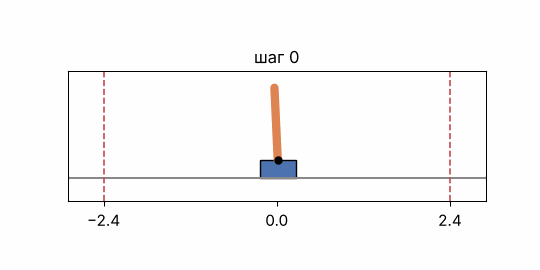

**Весь DQN в шести шагах** — их делает `train_dqn`, и они же нарисованы на схеме:

1. выбрать действие: с наибольшим $Q_\theta$, изредка случайное;
2. сделать шаг, переход — в буфер;
3. взять из буфера случайную пачку;
4. посчитать цель $y$ копией $\bar\theta$;
5. сделать шаг градиента по $\big(y - Q_\theta(s, a)\big)^2$;
6. подтянуть копию к $\theta$ на 1 %.

**Одной строкой:** DQN = Q-сеть + буфер опыта (разнообразные данные) + целевая сеть (цель, которую шаг обучения не сдвигает).

## 4. Тот же DQN сажает лунный модуль

**Главная идея: в DQN нет ничего про шест — тот же алгоритм учится управлять другим физическим объектом, меняются только размеры сети.**

Задача — посадить модуль на площадку. Это среда `LunarLander` из Gymnasium, движение модуля считает физический движок Box2D.

* **Состояние** — 8 чисел: координаты $x$ и $y$, две скорости, угол наклона, угловая скорость и два признака «опора касается грунта».
* **Действия** — 4: ничего не делать, включить левый, главный или правый двигатель.
* **Награда** — плюс за приближение к площадке и гашение скорости, минус за наклон и расход топлива; $+100$ за посадку, $-100$ за аварию.
* **Конец эпизода** — модуль сел, разбился или улетел за край.

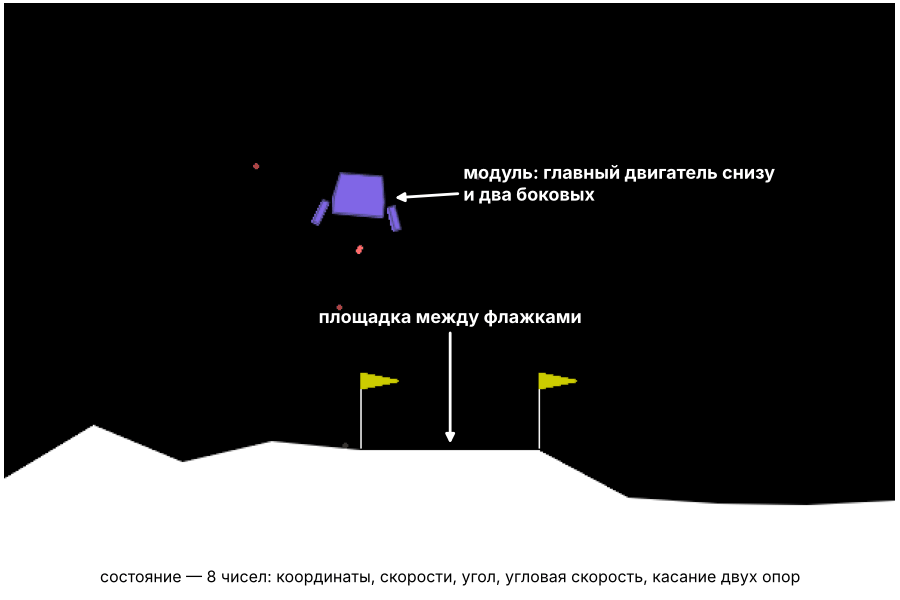

**Вопрос 4.** Что придётся поменять в `train_dqn`, чтобы вместо шеста учиться сажать модуль?

* **A.** почти всё: шест и модуль — разные задачи;
* **B.** формулу цели $y$: награды здесь другие;
* **C.** размеры сети: 8 чисел на входе, 4 на выходе;
* **D.** убрать буфер: эпизоды у модуля длиннее.

Ответ **C — размеры сети**: на входе 8 чисел вместо 4, на выходе 4 оценки вместо 2. Буфер, цель от копии сети и сдвиг копии на 1 % — те же строки. Ещё мы дали сети больше времени: 600 эпизодов вместо 300, и случайных действий поначалу больше — $\varepsilon$ падает за 20 000 шагов, а не за 5000. Обучение идёт около 6 минут, поэтому оно вынесено из ноутбука в `lander.py`; там тот же цикл из четырёх блоков.

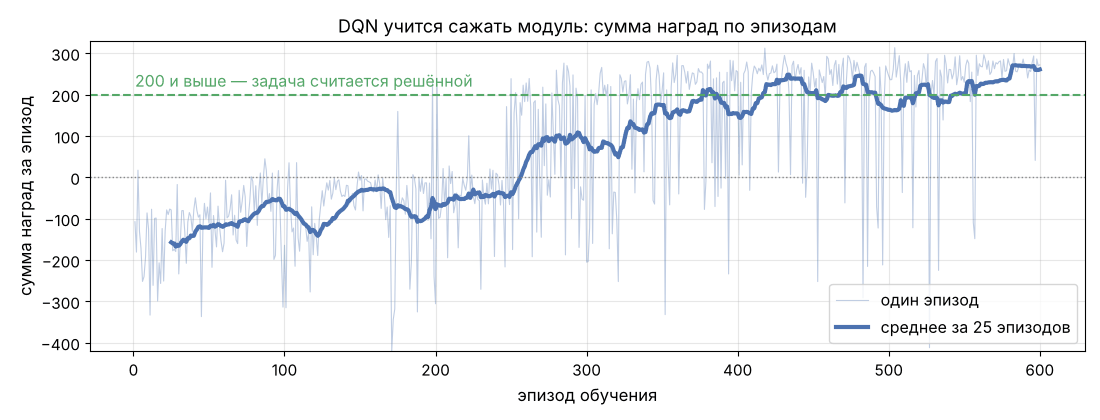

Первые 50 эпизодов модуль набирает в среднем −140: падает и разбивается. Последние 50 — в среднем 248. На 20 новых эпизодах без случайных действий сеть набрала в среднем 270, и в 19 из 20 — не меньше 200.

Один и тот же старт: слева сеть до обучения, справа — после.

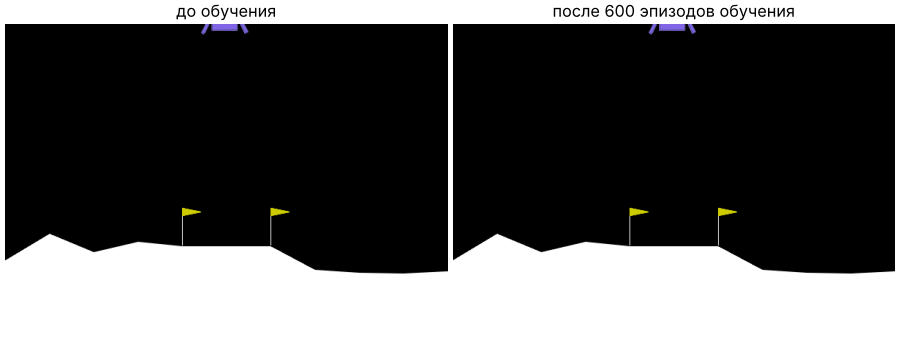

> **Простыми словами.** Алгоритму не нужны формулы физики: агент получает числа, пробует действия и учится по наградам. Поэтому один и тот же код управляет и шестом, и посадочным модулем.

**Одной строкой:** DQN — общий алгоритм: чтобы управлять другим объектом, достаточно поменять размеры сети.

## 5. Double DQN: кто выбирает действие в цели

**Главная идея: $\max$ в цели и выбирает действие, и оценивает его одними и теми же шумными числами — такая оценка в среднем завышена. Double DQN выбирает действие основной сетью, а оценивает копией.**

Оценки сети всегда содержат ошибку. Посмотрим, что делает с ошибками $\max$, на задаче, где ответ известен заранее.

**Вопрос 5.** У двух действий настоящая ценность одинаковая — 0. К оценке каждого прибавлена случайная ошибка: в среднем нулевая, со стандартным отклонением 1. В цель идёт $\max$ из двух оценок. Чему он равен в среднем по многим повторам?

* **A.** 0 — ошибки в среднем нулевые;
* **B.** больше 0;
* **C.** меньше 0;
* **D.** то больше, то меньше — в среднем не определить.

Проверим на 100 000 повторов. Вторая пара оценок `second` — тех же двух действий, с независимыми ошибками; она понадобится для третьей гистограммы.

хотя бы одна из двух оценок выше 0: в 75% повторов


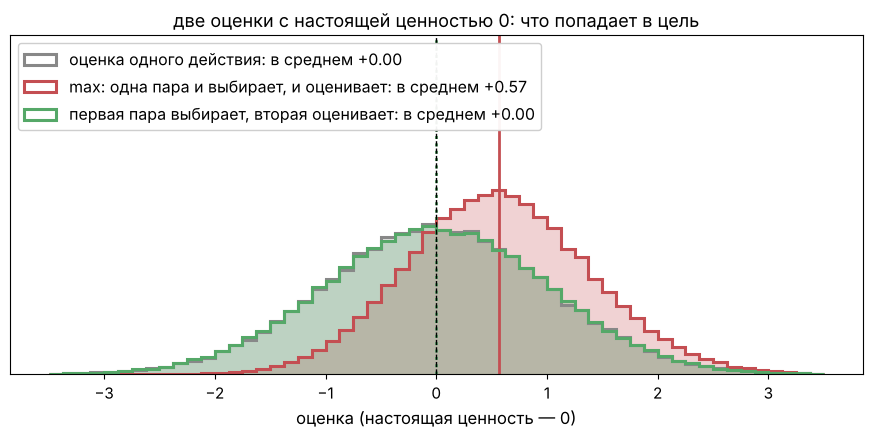

In [13]:
rng = np.random.default_rng(0)
first = rng.normal(size=(100_000, 2))          # массив 100 000 × 2: оценки двух действий, настоящая ценность 0
second = rng.normal(size=(100_000, 2))         # вторая пара оценок тех же действий, ошибки независимые
rows = np.arange(100_000)
samples = {"оценка одного действия": first[:, 0],
           "max: одна пара и выбирает, и оценивает": first.max(axis=1),
           "первая пара выбирает, вторая оценивает": second[rows, first.argmax(axis=1)]}
print(f"хотя бы одна из двух оценок выше 0: в {(first.max(axis=1) > 0).mean():.0%} повторов")
plot_max_bias(samples, title="две оценки с настоящей ценностью 0: что попадает в цель")
plt.show()

Ответ **B — больше 0**: в среднем +0.57. Каждая оценка по отдельности честная — в среднем 0. Но $\max$ берёт ту, чья ошибка в этом повторе больше, а хотя бы одна из двух ошибок положительна в 75 % повторов ($1 - 0.5 \cdot 0.5$).

Третья гистограмма — лечение: действие выбирает первая пара оценок, а число берётся из второй. Её ошибка с выбором не связана, и среднее снова 0.

В цели DQN обе работы делают числа копии:

$$
\max_{a'} Q_{\bar\theta}(s', a') \;=\; Q_{\bar\theta}\big(s',\ \underbrace{\arg\max_{a'} Q_{\bar\theta}(s', a')}_{\text{выбирает копия}}\big).
$$

Вторая сеть у нас уже есть. В **Double DQN** действие выбирает основная сеть, а оценивает его копия:

$$
y \;=\; r + \gamma\,(1 - \text{конец})\; Q_{\bar\theta}\big(s',\ \underbrace{\arg\max_{a'} Q_{\theta}(s', a')}_{\text{выбирает основная сеть}}\big).
$$

В коде меняется одна строка `train_dqn` — вместо `td_targets(target_net, R, S2, D)`:

In [14]:
def double_targets(qnet, target_net, R, S2, D, gamma=0.99):
    with torch.no_grad():
        best = qnet(S2).argmax(dim=1)                                  # 64 номера действий: выбирает основная сеть
        return R + gamma * (1 - D) * q_of(target_net, S2, best)        # 64 числа: оценивает копия

В CartPole действий всего два, и в наших прогонах выигрыша от замены нет. В играх Atari, где действий до 18, Double DQN заметно уменьшил завышение оценок и улучшил игру (van Hasselt и др., 2016). Другие улучшения DQN — о том же: меньше опираться на собственные оценки и лучше использовать буфер.

| улучшение | что меняет |
|---|---|
| Double DQN | действие в цели выбирает основная сеть, оценивает копия |
| Prioritized replay | из буфера чаще берутся переходы с большой ошибкой $\lvert y - Q \rvert$ |
| n-step | в цели $n$ настоящих наград подряд и только потом своя оценка |
| Rainbow | эти и ещё несколько улучшений вместе |

> **Простыми словами.** Если из нескольких шумных оценок всегда брать наибольшую, ошибаться будешь в одну сторону — вверх. Поэтому выбирает одна сеть, а число называет другая.

**Одной строкой:** Double DQN убирает завышение от $\max$: действие выбирает основная сеть, оценивает копия.

## 6. Итоги и где это работает

1. **Q-сеть с буфером опыта** держит шест 206–348 шагов, но оценка старта доходит до 210 279 при пределе 100.
2. **Причина — цель считает сама обучаемая сеть:** шаг к цели поднимает и цель. В примере «w и 2w» оценка за 100 шагов выросла с 1 до 2200 при нулевых наградах.
3. **Смертельная триада:** общие веса, своя оценка в цели, данные другой стратегии. Опасны только все три вместе; третье условие добавил буфер.
4. **Целевая сеть** — копия, которая подтягивается к основной сети на 1 % за шаг и считает цель. **DQN = Q-сеть + буфер + целевая сеть:** шест стоит 273–416 шагов, наибольшая оценка старта 114–131; лучшая сеть без случайных шагов держит шест все 500 шагов.
5. **DQN — общий алгоритм.** С сетью 8 → 64 → 64 → 4 тот же код учится сажать лунный модуль: средняя сумма наград выросла с −140 до 248, на новых эпизодах 19 посадок из 20 набирают не меньше 200.
6. **Double DQN:** max из шумных оценок в среднем завышен (+0.57 на двух действиях с ценностью 0); действие в цели выбирает основная сеть, оценивает копия.

**Где это работает.** Игры Atari: DQN (Mnih и др., 2015) одной и той же программой играл в 49 игр, глядя только на экран, и больше чем в половине из них — не хуже человека. Алгоритм тот же, что у нас: буфер опыта (на миллион переходов) и целевая сеть. Другая только сама Q-сеть — свёрточная, она читает картинку.

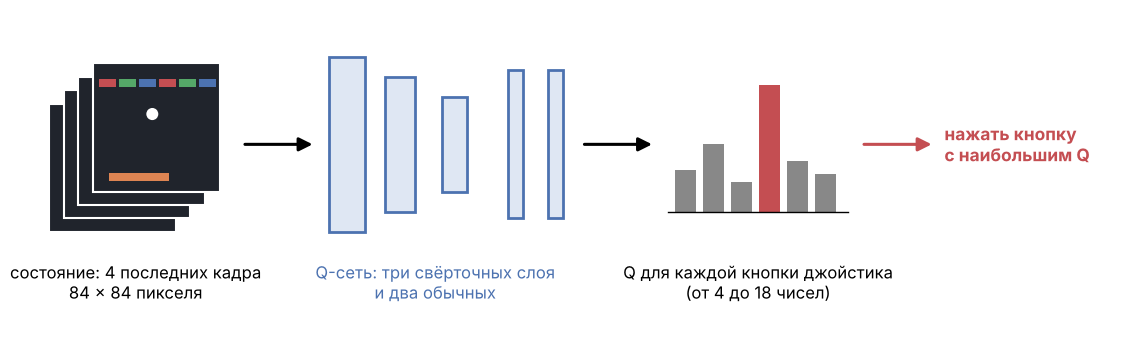

In [15]:
draw_atari_scheme()
plt.show()

До DQN тот же принцип — сеть, которая оценивает позицию и учится на своих же оценках, — сработал в нардах: TD-Gammon (Тезауро, 1992) играл на уровне сильнейших игроков.

> **Простыми словами — вся лекция.** Сеть, которая учится по собственным оценкам на старых данных, может поднимать эти оценки без конца. В DQN цель считает медленная копия сети — и оценки остаются возле настоящих.

Словарь лекции: **смертельная триада (аппроксимация, бутстрэппинг, off-policy), целевая сеть (target network), DQN, Double DQN**.

## Литература

* Mnih V. и др. *Human-level control through deep reinforcement learning*. Nature, 2015 — DQN на Atari.
* Саттон Р., Барто Э. *Обучение с подкреплением*, 2-е изд., глава 11: пример «w и 2w» — раздел 11.2, смертельная триада — раздел 11.3. [incompleteideas.net/book/the-book-2nd.html](http://incompleteideas.net/book/the-book-2nd.html)
* van Hasselt H., Guez A., Silver D. *Deep reinforcement learning with double Q-learning*. AAAI, 2016 — Double DQN.
* Hessel M. и др. *Rainbow: combining improvements in deep reinforcement learning*. AAAI, 2018 — обзор улучшений DQN.
* [Учебник по машинному обучению ШАД, глава «Обучение с подкреплением»](https://education.yandex.ru/handbook/ml/article/obuchenie-s-podkrepleniem).

## На семинаре и дома

* **Домашка блока 3** (лекция 5: градиент стратегии и REINFORCE) — дедлайн 22 ноября, 23:59 МСК.

In [16]:
print(f"ноутбук посчитался за {(time.time() - start_time) / 60:.0f} мин")

ноутбук посчитался за 11 мин
